    Loan_ID  Gender Married Dependents     Education Self_Employed  \
0  LP002314  Female      No          0  Not Graduate            No   
1  LP002315    Male     Yes          1      Graduate            No   
2  LP002317    Male     Yes         3+      Graduate            No   
3  LP002318  Female      No          1  Not Graduate           Yes   
4  LP002319    Male     Yes          0      Graduate           NaN   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             2213                0.0        66.0             360.0   
1             8300                0.0       152.0             300.0   
2            81000                0.0       360.0             360.0   
3             3867                0.0        62.0             360.0   
4             6256                0.0       160.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Rural           Y  
1             0.0     Semiurban           N  
2             

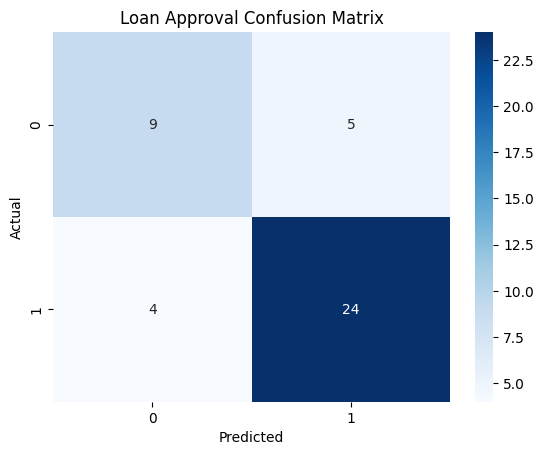

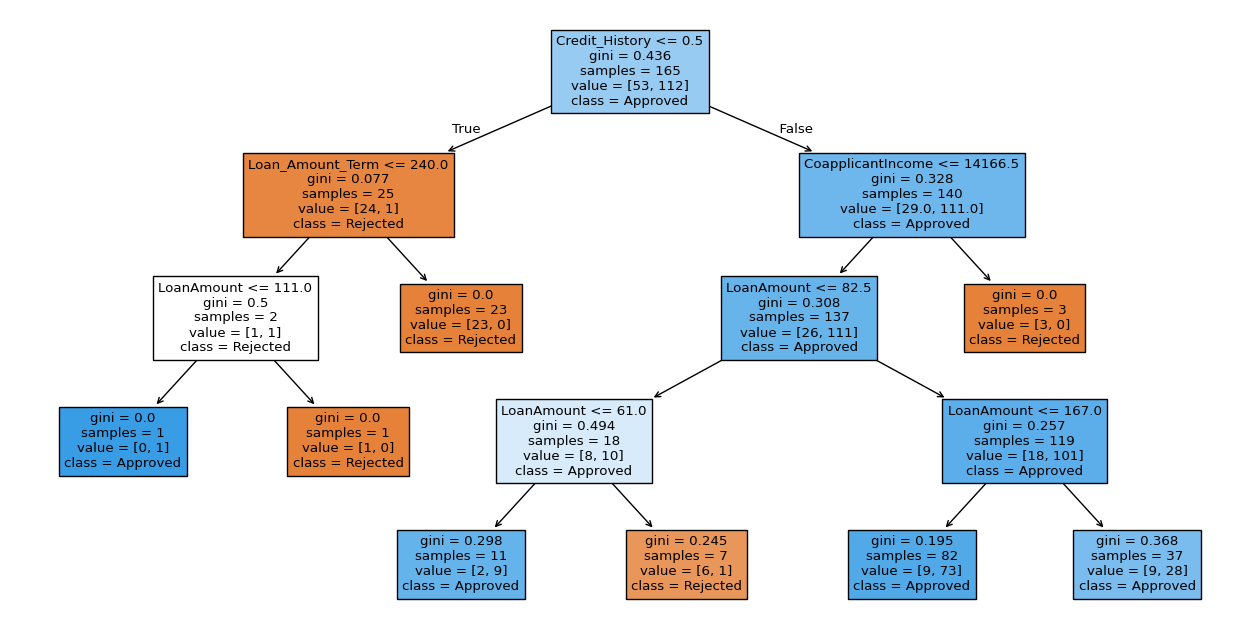

Sample prediction: Approved


In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_excel("loan.xlsx")

print(df.head())
print(df.isnull().sum())

df = df.drop(columns=["Loan_ID"])

df["Loan_Status"] = df["Loan_Status"].map({"Y": 1, "N": 0})

for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

df = pd.get_dummies(df, drop_first=True, dtype=int)

X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Loan Approval Confusion Matrix")
plt.show()

plt.figure(figsize=(16, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Rejected", "Approved"],
    filled=True
)
plt.show()

print("Sample prediction:",
      "Approved" if model.predict(X_test.iloc[[0]])[0] == 1 else "Rejected")
